<a href="https://colab.research.google.com/github/DinaKSari/PCVK_2026_2027/blob/main/week10_05.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
#import library yang dibutuhkan
import cv2 as cv
import numpy as np
from matplotlib import pyplot as plt
#akses drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


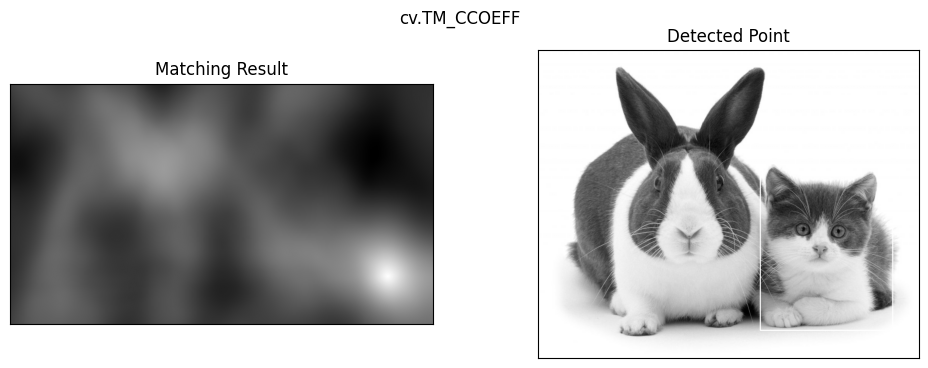

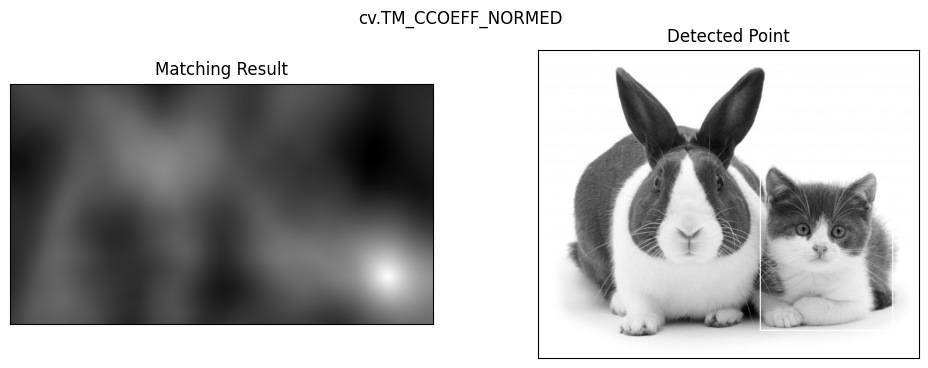

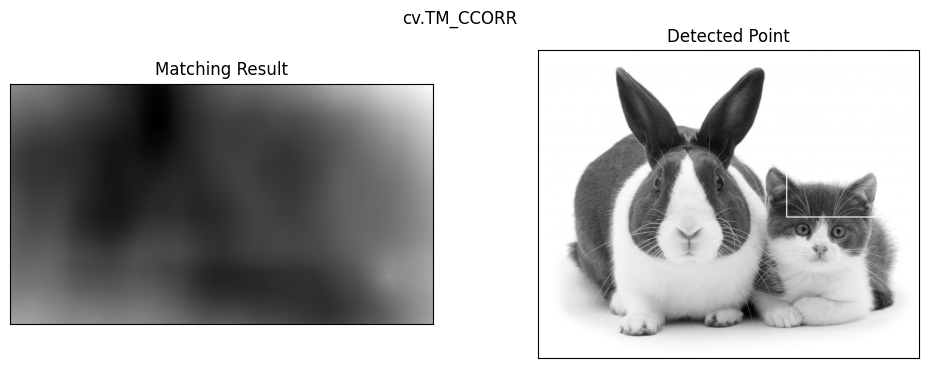

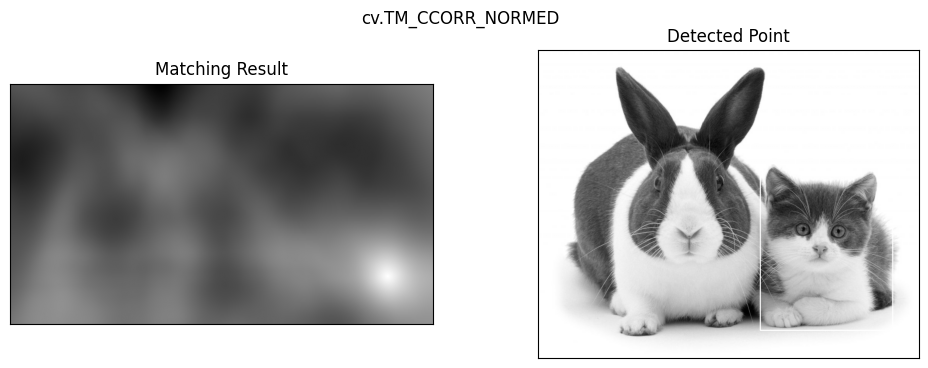

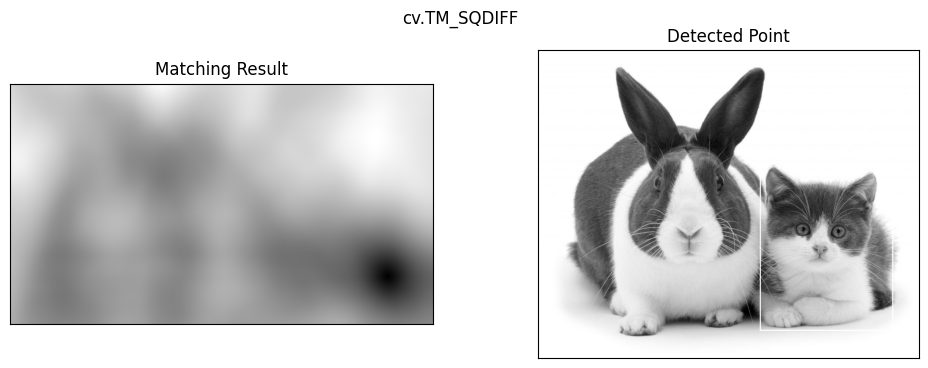

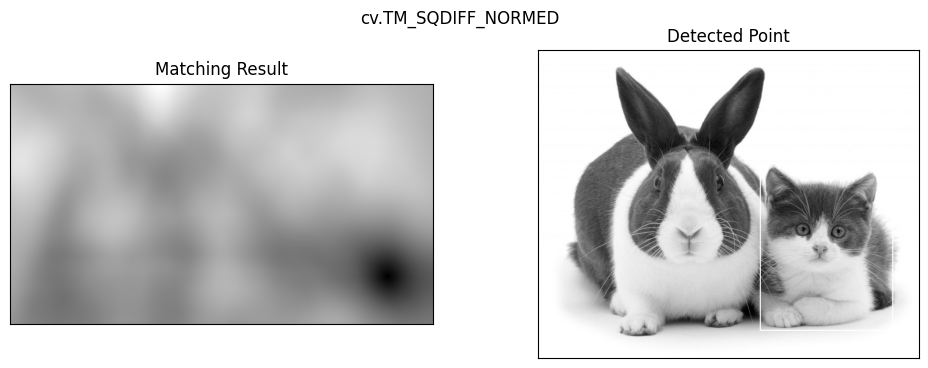

In [13]:
import os

path_img = '/content/drive/MyDrive/PCVK/Images/244107020072/ImagesObjectDetection/cats_and_bunnies.jpg'
path_template = '/content/drive/MyDrive/PCVK/Images/244107020072/ImagesObjectDetection/cat2_template.jpg'

img = cv.imread(path_img, 0)
template = cv.imread(path_template, 0)

if img is None:
    print(f"Error: Gambar tidak ditemukan di path: {path_img}")
elif template is None:
    print(f"Error: Template tidak ditemukan di path: {path_template}")
else:
    img2 = img.copy()
    w, h = template.shape[::-1]

    methods = ['cv.TM_CCOEFF', 'cv.TM_CCOEFF_NORMED', 'cv.TM_CCORR',
               'cv.TM_CCORR_NORMED', 'cv.TM_SQDIFF', 'cv.TM_SQDIFF_NORMED']

    for meth in methods:
        img = img2.copy()
        method = eval(meth)

        res = cv.matchTemplate(img, template, method)
        min_val, max_val, min_loc, max_loc = cv.minMaxLoc(res)

        if method in [cv.TM_SQDIFF, cv.TM_SQDIFF_NORMED]:
            top_left = min_loc
        else:
            top_left = max_loc
        bottom_right = (top_left[0] + w, top_left[1] + h)

        cv.rectangle(img, top_left, bottom_right, 255, 2)

        plt.figure(figsize=(12, 4))
        plt.subplot(121), plt.imshow(res, cmap='gray')
        plt.title('Matching Result'), plt.xticks([]), plt.yticks([])
        plt.subplot(122), plt.imshow(img, cmap='gray')
        plt.title('Detected Point'), plt.xticks([]), plt.yticks([])
        plt.suptitle(meth)
        plt.show()

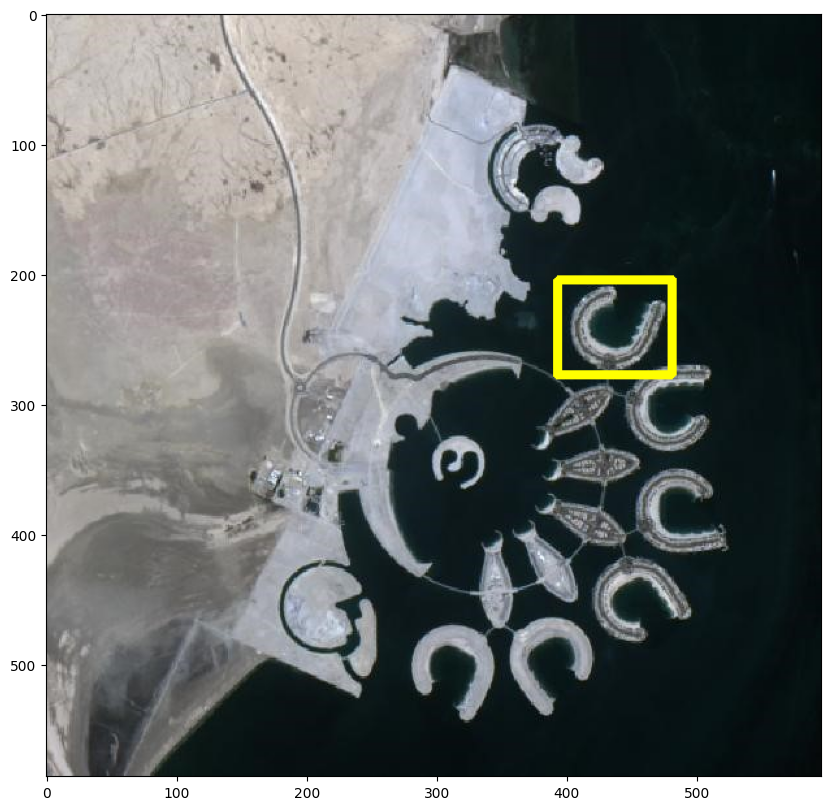

In [11]:
img_rgb = cv.imread('/content/drive/MyDrive/PCVK/Images/244107020072/ImagesObjectDetection/bahrain.jpg')
img_gray = cv.cvtColor(img_rgb, cv.COLOR_BGR2GRAY)
template = cv.imread('/content/drive/MyDrive/PCVK/Images/244107020072/ImagesObjectDetection/bahrain-template.jpg', 0)
w, h = template.shape[::-1]

res = cv.matchTemplate(img_gray, template, cv.TM_CCOEFF_NORMED)
threshold = 0.8
loc = np.where(res >= threshold)

for pt in zip(*loc[::-1]):
    cv.rectangle(img_rgb, pt, (pt[0] + w, pt[1] + h), (0, 255, 255), 2)

plt.figure(figsize=(10, 10))
plt.imshow(cv.cvtColor(img_rgb, cv.COLOR_BGR2RGB))
plt.show()

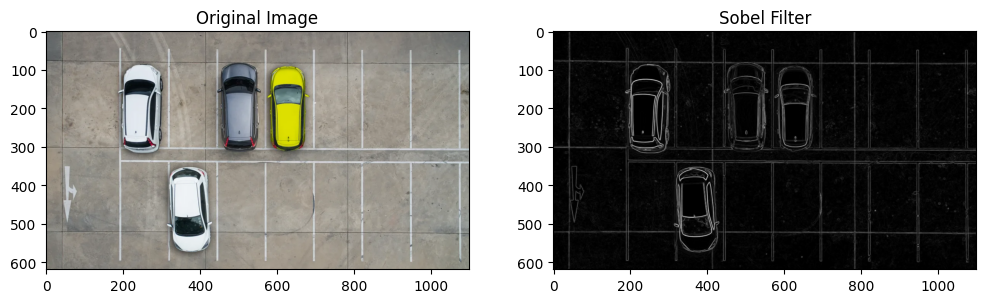

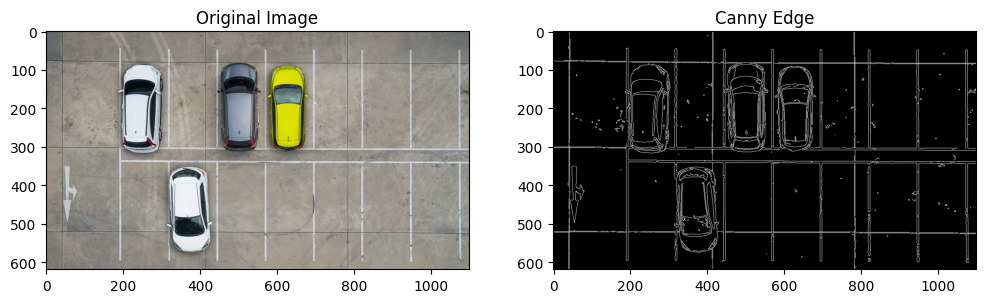

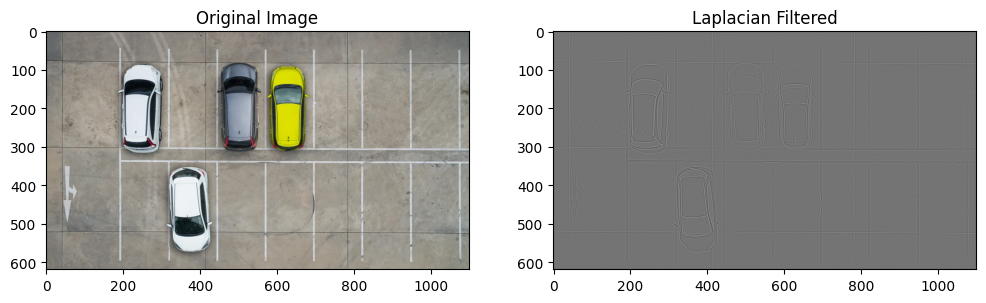

In [14]:
img = cv.imread('/content/drive/MyDrive/PCVK/Images/244107020072/ImagesObjectDetection/car-park.jpg')
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

# a. Sobel Edge Detection
sobelx = cv.Sobel(gray, cv.CV_64F, 1, 0, ksize=3)
sobely = cv.Sobel(gray, cv.CV_64F, 0, 1, ksize=3)
sobel_combined = cv.magnitude(sobelx, sobely)

plt.figure(figsize=(12, 6))
plt.subplot(121), plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB)), plt.title('Original Image')
plt.subplot(122), plt.imshow(sobel_combined, cmap='gray'), plt.title('Sobel Filter')
plt.show()

# b. Canny Edge Detection
canny = cv.Canny(gray, 100, 200)

plt.figure(figsize=(12, 6))
plt.subplot(121), plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB)), plt.title('Original Image')
plt.subplot(122), plt.imshow(canny, cmap='gray'), plt.title('Canny Edge')
plt.show()

# c. Laplacian Edge Detection
laplacian = cv.Laplacian(gray, cv.CV_64F)

plt.figure(figsize=(12, 6))
plt.subplot(121), plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB)), plt.title('Original Image')
plt.subplot(122), plt.imshow(laplacian, cmap='gray'), plt.title('Laplacian Filtered')
plt.show()

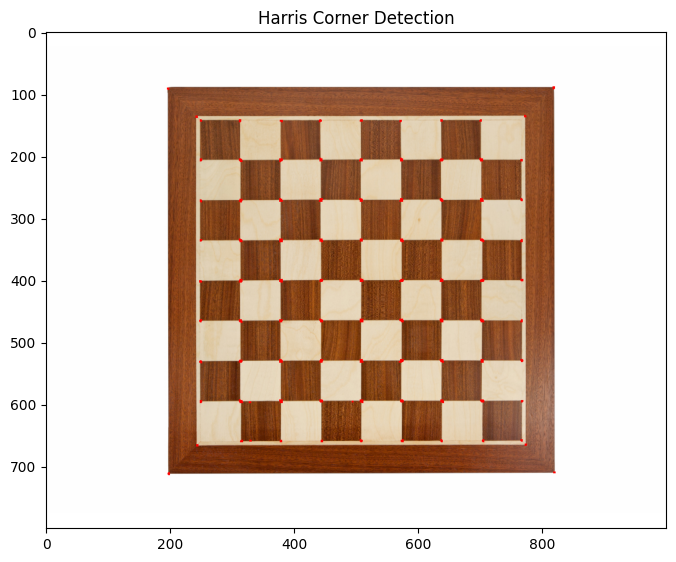

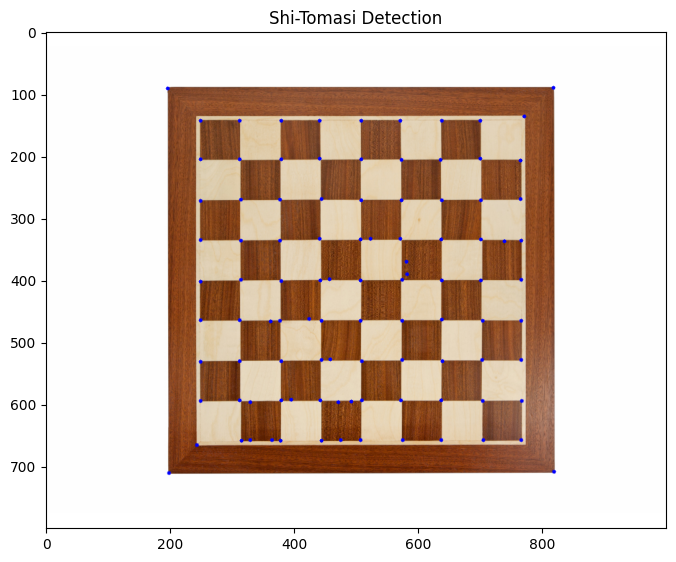

In [16]:
img = cv.imread('/content/drive/MyDrive/PCVK/Images/244107020072/ImagesObjectDetection/chess-board.jpg')
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

# a. Harris Corner Detection
gray_harris = np.float32(gray)
dst = cv.cornerHarris(gray_harris, 2, 3, 0.04)
dst = cv.dilate(dst, None)
img_harris = img.copy()
img_harris[dst > 0.01 * dst.max()] = [0, 0, 255]

plt.figure(figsize=(8, 8))
plt.imshow(cv.cvtColor(img_harris, cv.COLOR_BGR2RGB))
plt.title('Harris Corner Detection')
plt.show()

# b. Shi-Tomasi Detection
corners = cv.goodFeaturesToTrack(gray, 100, 0.01, 10)
corners = np.intp(corners)
img_shitomasi = img.copy()
for i in corners:
    x, y = i.ravel()
    cv.circle(img_shitomasi, (x, y), 3, (255, 0, 0), -1)

plt.figure(figsize=(8, 8))
plt.imshow(cv.cvtColor(img_shitomasi, cv.COLOR_BGR2RGB))
plt.title('Shi-Tomasi Detection')
plt.show()

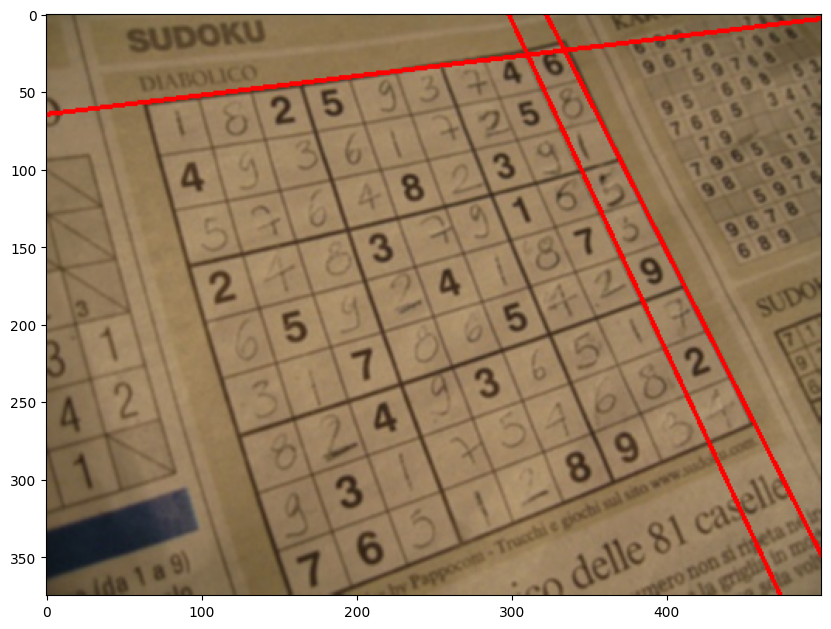

In [17]:
img = cv.imread('/content/drive/MyDrive/PCVK/Images/244107020072/ImagesObjectDetection/sudoku.jpg')
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
edges = cv.Canny(gray, 50, 150, apertureSize=3)

lines = cv.HoughLines(edges, 1, np.pi/180, 200)
for r_theta in lines:
    arr = np.array(r_theta[0], dtype=np.float64)
    r, theta = arr
    a = np.cos(theta)
    b = np.sin(theta)
    x0 = a*r
    y0 = b*r
    x1 = int(x0 + 1000*(-b))
    y1 = int(y0 + 1000*(a))
    x2 = int(x0 - 1000*(-b))
    y2 = int(y0 - 1000*(a))
    cv.line(img, (x1, y1), (x2, y2), (0, 0, 255), 2)

plt.figure(figsize=(10, 10))
plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
plt.show()

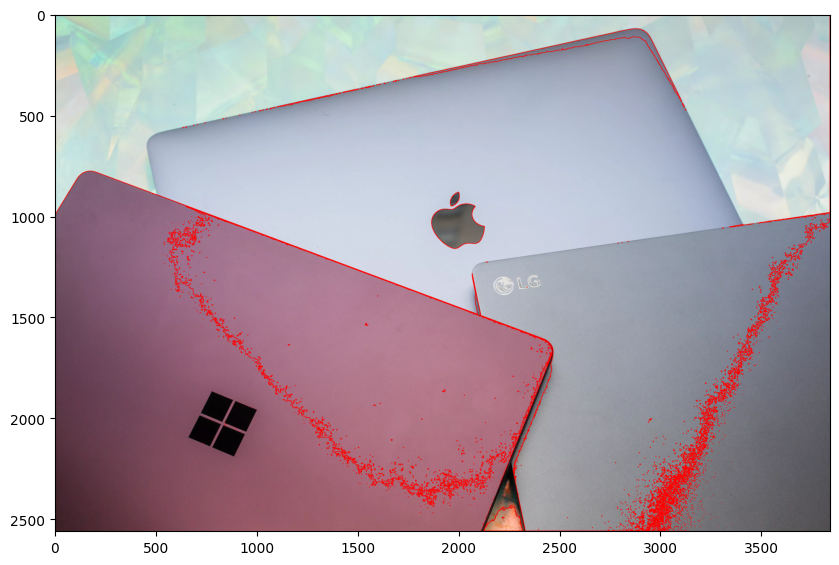

In [18]:
img = cv.imread('/content/drive/MyDrive/PCVK/Images/244107020072/ImagesObjectDetection/laptop.jpg')
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
ret, thresh = cv.threshold(gray, 127, 255, 0)
contours, hierarchy = cv.findContours(thresh, cv.RETR_TREE, cv.CHAIN_APPROX_SIMPLE)

img_contour = img.copy()
cv.drawContours(img_contour, contours, -1, (0, 0, 255), 2)

plt.figure(figsize=(10, 10))
plt.imshow(cv.cvtColor(img_contour, cv.COLOR_BGR2RGB))
plt.show()

In [20]:
import os

# Menentukan path file XML cascade dan gambar
xml_path = '/content/drive/MyDrive/PCVK/Images/244107020072/haarcascades/haarcascade_frontalface_alt.xml'
if not os.path.exists(xml_path):
    # Mencoba path alternatif jika ada struktur folder yang berbeda
    xml_path = '/content/drive/MyDrive/PCVK/Images/244107020072/ImagesObjectDetection/haarcascades/haarcascade_frontalface_alt.xml'

cascade_wajah = cv.CascadeClassifier(xml_path)
prabowo = cv.imread('/content/drive/MyDrive/PCVK/Images/244107020072/prabowo.jpg', 0)

if cascade_wajah.empty():
    print(f"Error: Gagal memuat Haar Cascade XML. Berkas tidak ditemukan di: {xml_path}")
elif prabowo is None:
    print("Error: Gagal membaca gambar prabowo.jpg. Periksa kembali path gambar Anda.")
else:
    roi_wajah = cascade_wajah.detectMultiScale(prabowo)

    for (x,y,w,h) in roi_wajah:
        cv.rectangle(prabowo, (x,y), (x+w,y+h), (255,255,255), 1)

    plt.figure(figsize=(10,10))
    plt.imshow(prabowo, cmap='gray')
    plt.show()

Error: Gagal memuat Haar Cascade XML. Berkas tidak ditemukan di: /content/drive/MyDrive/PCVK/Images/244107020072/ImagesObjectDetection/haarcascades/haarcascade_frontalface_alt.xml


In [ ]:
cascade_cat = cv.CascadeClassifier('/content/drive/MyDrive/PCVK/Images/244107020072/haarcascades/haarcascade_frontalcatface.xml')
cat_img = cv.imread('/content/drive/MyDrive/PCVK/Images/244107020072/ImagesObjectDetection/cat.jpg', 0)
faces = cascade_cat.detectMultiScale(cat_img, scaleFactor=1.1, minNeighbors=5, minSize=(30, 30))

for (x, y, w, h) in faces:
    cv.rectangle(cat_img, (x, y), (x + w, y + h), (255, 255, 255), 2)

plt.figure(figsize=(8, 8))
plt.imshow(cat_img, cmap='gray')
plt.show()

In [ ]:
cascade_wajah = cv.CascadeClassifier('/content/drive/MyDrive/PCVK/Images/244107020072/haarcascades/haarcascade_frontalface_alt.xml')
cascade_mata = cv.CascadeClassifier('/content/drive/MyDrive/PCVK/Images/244107020072/haarcascades/haarcascade_eye.xml')

prabowo = cv.imread('/content/drive/MyDrive/PCVK/Images/244107020072/prabowo.jpg', 0)
faces = cascade_wajah.detectMultiScale(prabowo, 1.3, 5)

for (x, y, w, h) in faces:
    cv.rectangle(prabowo, (x, y), (x + w, y + h), (255, 255, 255), 2)
    roi_gray = prabowo[y:y + h, x:x + w]
    eyes = cascade_mata.detectMultiScale(roi_gray)
    for (ex, ey, ew, eh) in eyes:
        cv.rectangle(roi_gray, (ex, ey), (ex + ew, ey + eh), (255, 255, 255), 2)

plt.figure(figsize=(10, 10))
plt.imshow(prabowo, cmap='gray')
plt.show()

In [ ]:
cascade_smile = cv.CascadeClassifier('/content/drive/MyDrive/PCVK/Images/244107020072/haarcascades/haarcascade_smile.xml')
cascade_face = cv.CascadeClassifier('/content/drive/MyDrive/PCVK/Images/244107020072/haarcascades/haarcascade_frontalface_default.xml')

img = cv.imread('/content/drive/MyDrive/PCVK/Images/244107020072/ImagesObjectDetection/people.jpg')
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
faces = cascade_face.detectMultiScale(gray, 1.3, 5)

for (x, y, w, h) in faces:
    cv.rectangle(img, (x, y), (x + w, y + h), (0, 255, 0), 2)
    roi_gray = gray[y:y + h, x:x + w]
    roi_color = img[y:y + h, x:x + w]
    smiles = cascade_smile.detectMultiScale(roi_gray, 1.8, 20)
    for (sx, sy, sw, sh) in smiles:
        cv.rectangle(roi_color, (sx, sy), (sx + sw, sy + sh), (255, 0, 0), 2)

plt.figure(figsize=(12, 8))
plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
plt.show()

In [21]:
from IPython.display import display, Javascript
from google.colab.output import eval_js
from base64 import b64decode

def take_photo(filename='photo.jpg', quality=0.8):
  js = Javascript('''
    async function takePhoto(quality) {
      const div = document.createElement('div');
      const capture = document.createElement('button');
      capture.textContent = 'Capture';
      div.appendChild(capture);

      const video = document.createElement('video');
      video.style.display = 'block';
      const stream = await navigator.mediaDevices.getUserMedia({video: {facingMode: 'user'}});

      document.body.appendChild(div);
      div.appendChild(video);
      video.srcObject = stream;
      await video.play();

      google.colab.output.setIframeHeight(document.documentElement.scrollHeight, true);

      await new Promise((resolve) => capture.onclick = resolve);

      const canvas = document.createElement('canvas');
      canvas.width = video.videoWidth;
      canvas.height = video.videoHeight;
      canvas.getContext('2d').drawImage(video, 0, 0);
      stream.getVideoTracks()[0].stop();
      div.remove();
      return canvas.toDataURL('image/jpeg', quality);
    }
    ''')
  display(js)
  data = eval_js('takePhoto({})'.format(quality))
  binary = b64decode(data.split(',')[1])
  with open(filename, 'wb') as f:
    f.write(binary)
  return filename

try:
  filename = take_photo()
  print('Saved to {}'.format(filename))

  img = cv2.imread(filename)
  gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
  face_cascade = cv2.CascadeClassifier('/content/drive/MyDrive/PCVK/Images/244107020072/haarcascades/haarcascade_frontalface_default.xml')
  faces = face_cascade.detectMultiScale(gray, 1.3, 5)
  for (x, y, w, h) in faces:
    cv2.rectangle(img, (x, y), (x+w, y+h), (255, 0, 0), 2)

  plt.figure(figsize=(8, 8))
  plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
  plt.show()

except Exception as err:
  print(str(err))

<IPython.core.display.Javascript object>

NotAllowedError: Permission denied


In [ ]:
cascade_wajah = cv.CascadeClassifier('/content/drive/MyDrive/PCVK/Images/244107020072/haarcascades/haarcascade_frontalface_alt.xml')
img = cv.imread('/content/drive/MyDrive/PCVK/Images/244107020072/prabowo.jpg')
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
faces = cascade_wajah.detectMultiScale(gray, 1.3, 5)

for (x, y, w, h) in faces:
    face_roi = img[y:y+h, x:x+w]
    blurred_face = cv.medianBlur(face_roi, 35)
    img[y:y+h, x:x+w] = blurred_face

plt.figure(figsize=(10, 10))
plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
plt.show()

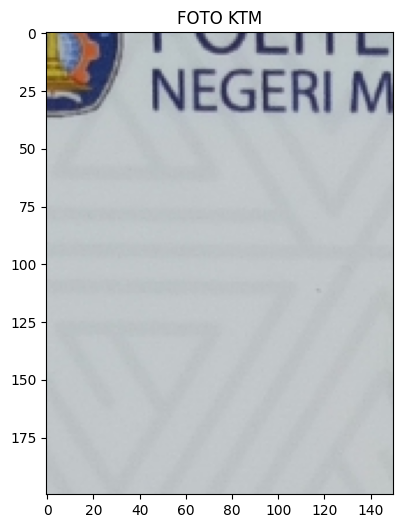

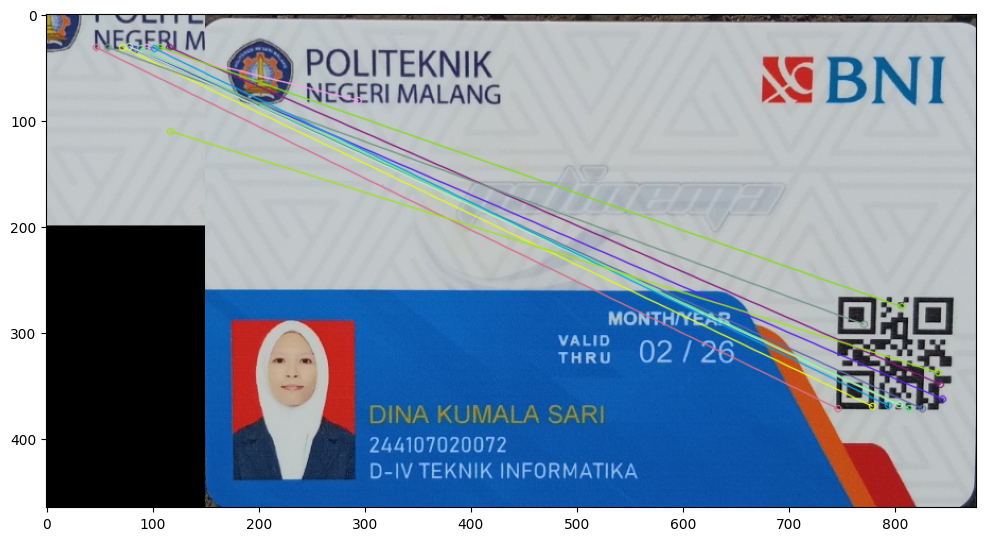

In [23]:
ktm = cv.imread('/content/drive/MyDrive/PCVK/Images/244107020072/ktm-dina.jpg')
foto_ktm = ktm[50:250, 50:200]

plt.figure(figsize=(6, 6))
plt.imshow(cv.cvtColor(foto_ktm, cv.COLOR_BGR2RGB))
plt.title("FOTO KTM")
plt.show()

reeses = foto_ktm
cereals = ktm

orb = cv.ORB_create()
kp1, des1 = orb.detectAndCompute(reeses, None)
kp2, des2 = orb.detectAndCompute(cereals, None)
bf = cv.BFMatcher(cv.NORM_HAMMING, crossCheck=True)
matches = bf.match(des1, des2)
matches = sorted(matches, key=lambda x: x.distance)

ktm_match = cv.drawMatches(reeses, kp1, cereals, kp2, matches[:25], None, flags=2)
plt.figure(figsize=(12, 10))
plt.imshow(cv.cvtColor(ktm_match, cv.COLOR_BGR2RGB))
plt.show()

In [24]:
import os
import cv2
import random
import numpy as np
import pickle
from tqdm import tqdm

DATADIR = "/content/drive/MyDrive/PCVK/Images/244107020072/dataset/training"
width, height = 100, 100

dirs = sorted(os.listdir(DATADIR))
training_data = []

for char_name in dirs:
    path = os.path.join(DATADIR, char_name)
    class_number = dirs.index(char_name)
    for img in tqdm(os.listdir(path), desc=char_name):
        try:
            img_array = cv2.imread(os.path.join(path, img), cv2.IMREAD_GRAYSCALE)
            new_array = cv2.resize(img_array, (width, height))
            training_data.append([new_array, class_number])
        except Exception:
            pass

random.shuffle(training_data)

X, Y = [], []
for feature, label in training_data:
    X.append(feature)
    Y.append(label)

X = np.array(X).reshape(-1, width, height, 1)
Y = np.array(Y)

pickle.dump(X, open("X.pickle", "wb"))
pickle.dump(Y, open("Y.pickle", "wb"))
pickle.dump(dirs, open("kelas.pickle", "wb"))

print("jumlah data :", len(training_data))
print("jumlah kelas:", len(dirs), dirs)

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/PCVK/Images/244107020072/dataset/training'

In [ ]:
import pickle
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Flatten, Dense, ZeroPadding2D
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.utils import to_categorical

X = pickle.load(open("X.pickle", "rb"))
Y = pickle.load(open("Y.pickle", "rb"))

Y = to_categorical(Y)
X = X / 255.0
width, height = 100, 100
jumlah_kelas = Y.shape[1]

inputs = Input(shape=(width, height, 1))
conv_layer = ZeroPadding2D(padding=(2, 2))(inputs)
conv_layer = Conv2D(16, (5, 5), strides=(1, 1), activation='relu')(conv_layer)
conv_layer = MaxPooling2D((2, 2))(conv_layer)
conv_layer = Conv2D(32, (3, 3), strides=(1, 1), activation='relu')(conv_layer)
conv_layer = Conv2D(32, (3, 3), strides=(1, 1), activation='relu')(conv_layer)
conv_layer = MaxPooling2D((2, 2))(conv_layer)
conv_layer = Conv2D(64, (3, 3), strides=(1, 1), activation='relu')(conv_layer)
flaten = Flatten()(conv_layer)
fc_layer = Dense(256, activation='relu')(flaten)
fc_layer = Dense(64, activation='relu')(fc_layer)
outputs = Dense(jumlah_kelas, activation='softmax')(fc_layer)

model = Model(inputs=inputs, outputs=outputs)

model.compile(optimizer=Adam(learning_rate=0.0001),
              loss='categorical_crossentropy',
              metrics=['accuracy'])

riwayat = model.fit(X, Y, epochs=20, verbose=1, validation_split=0.2)
model.save('anpr.keras')

print("akurasi training :", riwayat.history['accuracy'][-1])
print("akurasi validasi :", riwayat.history['val_accuracy'][-1])

In [ ]:
import os
import cv2
import pickle
import numpy as np
import tensorflow as tf

data_dir_testing = "/content/drive/MyDrive/PCVK/Images/244107020072/dataset/testing"
width, height = 100, 100

model = tf.keras.models.load_model("anpr.keras")
dirs = pickle.load(open("kelas.pickle", "rb"))

for car in sorted(os.listdir(data_dir_testing)):
    temp = ""
    folder = os.path.join(data_dir_testing, car)
    for char_img in sorted(os.listdir(folder)):
        img_array = cv2.imread(os.path.join(folder, char_img), cv2.IMREAD_GRAYSCALE)
        new_array = cv2.resize(img_array, (width, height))
        new_array = new_array.reshape(-1, width, height, 1) / 255.0
        prediction = model.predict(new_array, verbose=0)
        temp += dirs[np.argmax(prediction[0])]
    print("folder name: {}, no: {}".format(car, temp))